In [86]:
import numpy as np
import pandas as pd
import spacy
from sklearn.model_selection import train_test_split


df = pd.read_csv(r'C:\Users\NemoL\Documents\ThomasMore\DerdeJaar\trimester3_1\AI_Frameworks\Labo\labo4\cliendDataIse')

X = df['CombinDiscription']
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state = 4)

In [87]:
#Read your train and test set

In [35]:
# train.drop("Unnamed: 0",axis=1 ,inplace=True)
# test.drop("Unnamed: 0",axis=1 ,inplace=True)

In [36]:
#Get the specific data as informed bellow
X_train
y_train

X_test
y_test

11           Software issue
143           Privacy issue
34           Software issue
171          Software issue
1      Purchase requisition
69           Software issue
153          Software issue
190           Privacy issue
48           Software issue
180    Purchase requisition
184    Purchase requisition
150    Purchase requisition
101    Purchase requisition
61            Privacy issue
93     Purchase requisition
185           Privacy issue
82            Privacy issue
191           Privacy issue
71           Software issue
181    Purchase requisition
89           Software issue
83           Software issue
155          Software issue
33     Purchase requisition
88           Software issue
110          Software issue
6             Privacy issue
14     Purchase requisition
121           Privacy issue
182    Purchase requisition
18           Software issue
154    Purchase requisition
177    Purchase requisition
165          Software issue
167          Software issue
99           Softwar

In [37]:
nlp = spacy.load('en_core_web_sm', disable = ['tagger','parser','ner'])

In [48]:
#Create a function to transform tickets in tokens


def tokenize(text):
    doc = nlp(text)

    tokens = pd.DataFrame([{
        "Text": token.text,
        "Lemma": token.lemma_,
        "POS": token.pos_,
        "Fine POS": token.tag_,
        "Dependency": token.dep_,
        "Head": token.head.text,
        "Is stop word": token.is_stop,
        "Is punctuation": token.is_punct,
        "Is alphabetic": token.is_alpha,
        "Shape": token.shape_,
    }for token in doc])
    tokens = tokens[(tokens["Is stop word"] == False) & (tokens["Is punctuation"] == False)]
    return " ".join(tokens["Lemma"])










In [49]:
from tqdm import tqdm

clean_train_tickets = []
for ticket in tqdm(X_train):
    clean_train_tickets.append(tokenize(ticket))

#Apply the previous function to the X_train
 

  0%|          | 0/135 [00:00<?, ?it/s]C:\Users\NemoL\Documents\ThomasMore\TweedeJaar\troimester2_2\Python for AI\Labo\PY_AI_Project1\project\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
100%|██████████| 135/135 [00:00<00:00, 281.74it/s]


In [50]:
clean_train_tickets

['rgb mode stuck lightsaber becomehmm problem installing latest security update broken lightsaber longer stable blade rgb mode displays red blue green flashing endlessly balance disco use battle impossible   jedi tool toy fix',
 'broken pchey thursday pc fell floor wanted know procedure require new sorry inconvenience thanks advance',
 "ergonomic chair purchasewe're running low ergonomic chairs office   order additional ergonomic chairs improve employee comfort",
 'privacy glass windowsit nice privacy glasses windows corporate building working street glass wall makes feel uncomfortable',
 'request updated design software licensethe current license design application appears expired preventing file export collaboration kindly initiate renewal process assign active license',
 'cuda cpu use wo workfor ai training want use gpu check requirements met cuda',
 'replacement malfunctioning input devicemy current keyboard intermittently fails register keystrokes significantly slowing report prep

In [72]:

from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(analyzer = 'word', max_features = 20)
#Create a CountVectorizer object
train_data_features = vectorizer.fit_transform(clean_train_tickets)

In [73]:
vocab = vectorizer.get_feature_names_out()
print(vectorizer)

CountVectorizer(max_features=20)


In [74]:
train_data_features[0].toarray()

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]])

In [75]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()

classifier.fit(train_data_features, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[45.,37.,53.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.1 ,-1.29,-0.93]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U20](3,)","['Privacy issue','Purchase requisition','Software issue']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 20)","[[13., 1., 8.,..., 1., 7., 2.], [ 1., 1., 7.,...,13., 4., 5.], [ 6., 9., 2.,...,12., 1., 5.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 20)","[[-2.42,-4.36,-2.86,...,-4.36,-2.98,-3.96], [-4.18,-4.18,-2.8 ,...,-2.24,-3.27,-3.08], [-2.97,-2.62,-3.82,...,-2.36,-4.23,-3.13]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20


Preprocess and transform the test set!

In [88]:
clean_test_reviews = []

for ticket in tqdm(X_test):
    clean_test_reviews.append(tokenize(ticket))

#perform the data processing in our test set 

  0%|          | 0/59 [00:00<?, ?it/s]C:\Users\NemoL\Documents\ThomasMore\TweedeJaar\troimester2_2\Python for AI\Labo\PY_AI_Project1\project\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
100%|██████████| 59/59 [00:00<00:00, 324.32it/s]


In [90]:
clean_test_reviews


['update issuesin recent update employees experiencing major technical issues recent update older computers especially experiencing issue update devices work correctly',
 'm workingwell m bored m making ticket look busy',
 'customer data sync errorcustomer changed email website update correctly',
 'software update problemsrequesting update project management software fix bugs improve functionality',
 'request new monitorswe need purchase 10 new high resolution monitors design team provide quotes specifications monitors meet requirements',
 'unable access corporate vpndear team   currently unable access corporate vpn preventing connecting internal network accessing essential resources investigate issue provide guidance resolve   kind regards nelli',
 'lockt outwell locked account password attempts best regards xandress',
 'privacy policy updateour privacy policy needs updated reflect recent changes data privacy regulations necessary revisions',
 'slow database querysome standard databas

In [91]:
test_data_features = vectorizer.transform(clean_test_reviews)
results = classifier.predict(test_data_features)
results

array(['Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Software issue', 'Privacy issue', 'Software issue',
       'Privacy issue', 'Software issue', 'Purchase requisition',
       'Purchase requisition', 'Privacy issue', 'Purchase requisition',
       'Privacy issue', 'Privacy issue', 'Privacy issue',
       'Purchase requisition', 'Software issue', 'Software issue',
       'Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Privacy issue', 'Privacy issue',
       'Purchase requisition', 'Purchase requisition',
       'Purchase requisition', 'Software issue', 'Privacy issue',
       'Software issue', 'Software issue', 'Software issue',
       'Software issue', 'Software issue', 'Purchase requisition',
       'Purchase requisition', 'Purchase requisition',
       'Purchase requisition', 'Purchase requisition', 'Software issue',
       'Purchase requisition', 'Software issue', 'Soft

Check your score

In [81]:
#check the score

Look at your results and compare with your ground truth

In [92]:
#check the prediction
classifier.score(test_data_features, y_test)

0.6610169491525424

In [93]:
y_test

11           Software issue
143           Privacy issue
34           Software issue
171          Software issue
1      Purchase requisition
69           Software issue
153          Software issue
190           Privacy issue
48           Software issue
180    Purchase requisition
184    Purchase requisition
150    Purchase requisition
101    Purchase requisition
61            Privacy issue
93     Purchase requisition
185           Privacy issue
82            Privacy issue
191           Privacy issue
71           Software issue
181    Purchase requisition
89           Software issue
83           Software issue
155          Software issue
33     Purchase requisition
88           Software issue
110          Software issue
6             Privacy issue
14     Purchase requisition
121           Privacy issue
182    Purchase requisition
18           Software issue
154    Purchase requisition
177    Purchase requisition
165          Software issue
167          Software issue
99           Softwar

Plot a confusion matrix

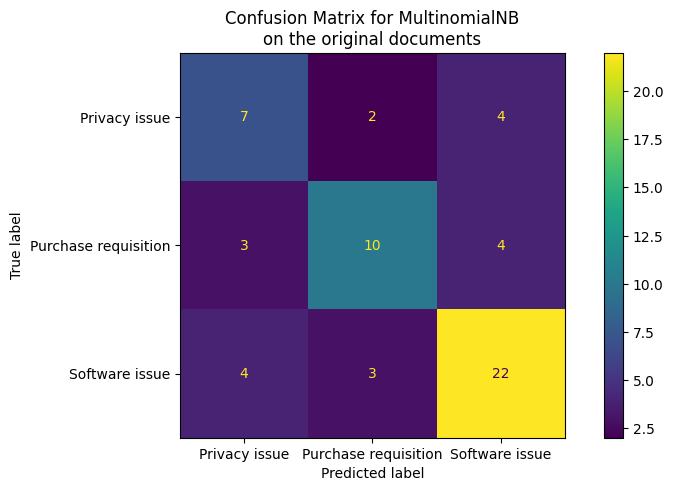

In [94]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

target_names = ['Privacy issue', 'Purchase requisition', 'Software issue']

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, results, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(f"Confusion Matrix for {classifier.__class__.__name__}\non the original documents")

**Not bad, right?**

Now is your time to play!


---> we use 5000 features, which can consist of unigrams (single words) or bigrams, when using the code below:

vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000,
                             ngram_range=(1,2))


What you should do:
- Try to check another parameters, another combination and train your naive bayes model

### Next

Apply other models:
- LogisticRegression
- BernoulliNB
- DecisionTreeClassifier



**Question:** Would you try a Neural Network in this data? Explain your thoughts.

i woud not fulli consider it cus ther isn not that mutch data for a NN